# 01 · NumPy Fundamentals

Working through the core ideas of NumPy: why arrays beat plain Python lists for numerical work,
how to create and inspect arrays, vectorised arithmetic, universal functions, indexing and slicing,
and two small simulations (coin flips and a random-walk stock price).

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# A seeded generator makes every random result in this notebook reproducible
rng = np.random.default_rng(seed=42)

## Python warm-up

In [2]:
# Jupyter displays the value of the last expression in a cell
1 + 1

2

In [3]:
a = 10
a + 1

11

In [4]:
# range(10) yields 0..9 - the stop value is excluded
for i in range(10):
    print(i)

0
1
2
3
4
5
6
7
8
9


## Plain Python lists vs NumPy arrays

Calculate speed (distance / time) for five trips, first with plain Python.

In [5]:
distances = [10, 15, 17, 26, 20]
times = [0.3, 0.47, 0.55, 1.20, 1.0]

# Loop version: index into both lists and append each result
speeds = []
for i in range(len(distances)):
    speeds.append(distances[i] / times[i])

speeds

[33.333333333333336,
 31.914893617021278,
 30.909090909090907,
 21.666666666666668,
 20.0]

In [6]:
# List comprehension with zip() - shorter and avoids manual indexing
[d / t for d, t in zip(distances, times)]

[33.333333333333336,
 31.914893617021278,
 30.909090909090907,
 21.666666666666668,
 20.0]

In [7]:
# Total value of an order: quantity x unit price, summed
product_quantities = [13, 5, 6, 10, 11]
prices = [1.2, 6.5, 1.0, 4.8, 5.0]
total = sum(q * p for q, p in zip(product_quantities, prices))
total

157.1

Convert the lists to NumPy arrays so the same calculations become single vectorised expressions.

In [8]:
distances = np.array(distances)
times = np.array(times)
product_quantities = np.array(product_quantities)
prices = np.array(prices)

distances

array([10, 15, 17, 26, 20])

In [9]:
type(distances)

numpy.ndarray

## Creating arrays

In [10]:
# A 2-D array is built from a list of lists (one inner list per row)
A = np.array([[1, 2], [3, 4]])
A

array([[1, 2],
       [3, 4]])

In [11]:
# Create a length-10 integer array filled with zeros
np.zeros(10, dtype=int)

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [12]:
# Create a 3x5 floating-point array filled with ones
np.ones(shape=(3, 5), dtype=float)

array([[1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.]])

In [13]:
# Create a linear sequence starting at 0, stepping by 2, stopping before 20
np.arange(start=0, stop=20, step=2)

array([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])

In [14]:
# Create 20 values evenly spaced between 0 and 1 (both ends included)
np.linspace(0, 1, 20)

array([0.        , 0.05263158, 0.10526316, 0.15789474, 0.21052632,
       0.26315789, 0.31578947, 0.36842105, 0.42105263, 0.47368421,
       0.52631579, 0.57894737, 0.63157895, 0.68421053, 0.73684211,
       0.78947368, 0.84210526, 0.89473684, 0.94736842, 1.        ])

## Array attributes

In [15]:
A = np.ones(shape=(3, 4), dtype=float)

# ndim = number of dimensions, shape = size of each dimension, size = total elements
print("ndim: ", A.ndim)
print("shape:", A.shape)
print("size: ", A.size)

ndim:  2
shape: (3, 4)
size:  12


## Vectorised operations

In [16]:
# Element-wise division - no loop needed
speeds = distances / times
speeds

array([33.33333333, 31.91489362, 30.90909091, 21.66666667, 20.        ])

In [17]:
values = product_quantities * prices
total = values.sum()
print(values)
total

[15.6 32.5  6.  48.  55. ]


157.1

In [18]:
x = np.arange(start=0, stop=20, step=2)

# Arithmetic with a scalar is applied to every element ("broadcasting")
print("x     :", x)
print("x + 1 :", x + 1)
print("x * 2 :", x * 2)
print("x / 2 :", x / 2)

x     : [ 0  2  4  6  8 10 12 14 16 18]
x + 1 : [ 1  3  5  7  9 11 13 15 17 19]
x * 2 : [ 0  4  8 12 16 20 24 28 32 36]
x / 2 : [0. 1. 2. 3. 4. 5. 6. 7. 8. 9.]


## Universal functions (ufuncs)

In [19]:
# ufuncs apply a mathematical function element-wise
np.sin(x)

array([ 0.        ,  0.90929743, -0.7568025 , -0.2794155 ,  0.98935825,
       -0.54402111, -0.53657292,  0.99060736, -0.28790332, -0.75098725])

In [20]:
np.exp(x)

array([1.00000000e+00, 7.38905610e+00, 5.45981500e+01, 4.03428793e+02,
       2.98095799e+03, 2.20264658e+04, 1.62754791e+05, 1.20260428e+06,
       8.88611052e+06, 6.56599691e+07])

In [21]:
# log(0) is -inf, so shift by 1 before taking the log
np.log(x + 1)

array([0.        , 1.09861229, 1.60943791, 1.94591015, 2.19722458,
       2.39789527, 2.56494936, 2.7080502 , 2.83321334, 2.94443898])

In [22]:
np.sqrt(x)

array([0.        , 1.41421356, 2.        , 2.44948974, 2.82842712,
       3.16227766, 3.46410162, 3.74165739, 4.        , 4.24264069])

## Indexing and slicing

In [23]:
one_dim = np.linspace(-0.5, 0.6, 12)
one_dim

array([-0.5, -0.4, -0.3, -0.2, -0.1,  0. ,  0.1,  0.2,  0.3,  0.4,  0.5,
        0.6])

In [24]:
# Indexing is zero-based: [5] is the sixth element
one_dim[5]

0.0

In [25]:
# Arrays are mutable - assign to an index to change an element
one_dim[0] = 1
one_dim

array([ 1. , -0.4, -0.3, -0.2, -0.1,  0. ,  0.1,  0.2,  0.3,  0.4,  0.5,
        0.6])

In [26]:
two_dim = np.array([[3, 5, 2, 4], [7, 6, 5, 5], [1, 6, -1, -1]])

# For 2-D arrays use [row, column]
print(two_dim[0, 3])
two_dim[0, 0] = -1
two_dim

4


array([[-1,  5,  2,  4],
       [ 7,  6,  5,  5],
       [ 1,  6, -1, -1]])

In [27]:
# Slices are [start:stop], with stop excluded; negative numbers count from the end
print(one_dim[2:5])   # elements 2, 3, 4
print(one_dim[:5])    # first five
print(one_dim[-5:])   # last five

[-0.3 -0.2 -0.1]
[ 1.  -0.4 -0.3 -0.2 -0.1]
[0.2 0.3 0.4 0.5 0.6]


In [28]:
# Top-left 2x2 block
two_dim[:2, :2]

array([[-1,  5],
       [ 7,  6]])

In [29]:
# All rows, columns 1 and 2
two_dim[:, 1:3]

array([[ 5,  2],
       [ 6,  5],
       [ 6, -1]])

## Reshaping

In [30]:
# reshape keeps the data but changes the shape (12 elements -> 4 rows x 3 columns)
one_dim.reshape(4, 3)

array([[ 1. , -0.4, -0.3],
       [-0.2, -0.1,  0. ],
       [ 0.1,  0.2,  0.3],
       [ 0.4,  0.5,  0.6]])

In [31]:
# flatten returns a 1-D copy of a multi-dimensional array
two_dim.flatten()

array([-1,  5,  2,  4,  7,  6,  5,  5,  1,  6, -1, -1])

## Simulation: flipping coins

Each experiment flips 10 fair coins (1 = heads, 0 = tails). Repeat it 10,000 times
and look at the distribution of the number of heads.

In [32]:
# integers(low, high) excludes high, so (0, 2) produces 0 or 1
rng.integers(low=0, high=2, size=1)

array([0])

In [33]:
experiment = rng.integers(0, 2, size=10)
print(experiment)
print("Heads:", experiment.sum())

[1 1 0 0 1 0 1 0 0 1]
Heads: 5


In [34]:
n_experiments = 10_000
coin_matrix = rng.integers(0, 2, size=(n_experiments, 10))
coin_matrix[:5, :]

array([[1, 1, 1, 1, 1, 1, 0, 1, 0, 1],
       [0, 0, 1, 1, 1, 0, 1, 1, 0, 0],
       [0, 0, 1, 1, 0, 1, 1, 0, 1, 0],
       [1, 1, 0, 0, 1, 0, 1, 1, 1, 1],
       [0, 0, 0, 0, 0, 1, 0, 1, 1, 1]])

In [35]:
# Sum across each row (axis=1) to get heads per experiment
counts = coin_matrix.sum(axis=1)
print(counts[:25])
print("mean:  ", counts.mean())
print("median:", np.median(counts))
print("min/max:", counts.min(), counts.max())
print("std:   ", counts.std())

[8 5 5 7 4 4 4 5 6 6 4 8 5 4 6 2 7 2 4 5 4 5 5 5 4]
mean:   5.0091
median: 5.0
min/max: 0 10
std:    1.576774299004141


In [36]:
# bincount tallies how often each value occurs; minlength=11 keeps all outcomes 0..10
observed_times = np.bincount(counts, minlength=11)
observed_times

array([   6,   94,  444, 1161, 2034, 2461, 2082, 1165,  448,   96,    9])

In [37]:
unique_numbers = np.arange(0, 11)
print("===============\n")
for n, count in zip(unique_numbers, observed_times):
    # Divide by the number of experiments to get the percentage
    print("{} heads observed {} times ({:0.1f}%)".format(n, count, 100 * count / n_experiments))


0 heads observed 6 times (0.1%)
1 heads observed 94 times (0.9%)
2 heads observed 444 times (4.4%)
3 heads observed 1161 times (11.6%)
4 heads observed 2034 times (20.3%)
5 heads observed 2461 times (24.6%)
6 heads observed 2082 times (20.8%)
7 heads observed 1165 times (11.7%)
8 heads observed 448 times (4.5%)
9 heads observed 96 times (1.0%)
10 heads observed 9 times (0.1%)


## Simulation: a random-walk stock price

Model 250 trading days of daily returns as normally distributed (mean 0.1%, std 2%).
Compounding the cumulative returns gives a simulated price path.

In [38]:
returns = rng.normal(loc=0.001, scale=0.02, size=250)
returns[:20]

array([-0.03525101, -0.00981316, -0.01657377, -0.01449705, -0.00207961,
       -0.01720034,  0.03453931,  0.01003333, -0.01488742, -0.0338087 ,
       -0.01066886, -0.00559419, -0.011699  ,  0.05184972, -0.03208397,
        0.00202068, -0.00159865, -0.00398263, -0.03778779,  0.00014453])

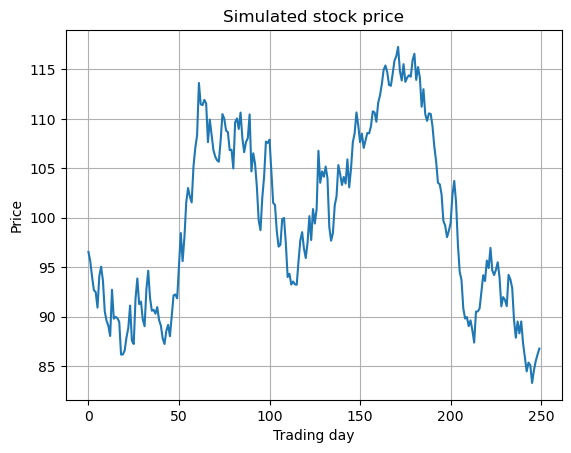

In [39]:
initial_price = 100

# Continuous compounding: price_t = P0 * exp(sum of returns up to t)
price = initial_price * np.exp(returns.cumsum())

fig, ax = plt.subplots()
ax.plot(price)
ax.set_title("Simulated stock price")
ax.set_xlabel("Trading day")
ax.set_ylabel("Price")
ax.grid();

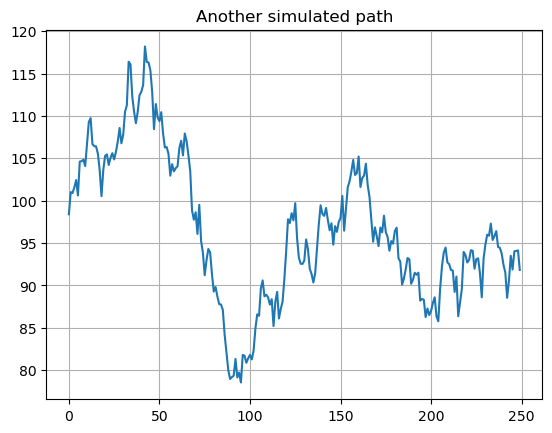

In [40]:
# Re-running the simulation gives a different path every time
returns = rng.normal(loc=0.001, scale=0.02, size=250)
price = initial_price * np.exp(returns.cumsum())

fig, ax = plt.subplots()
ax.plot(price)
ax.set_title("Another simulated path")
ax.grid();